In [1]:
import sys
sys.path.insert(0, '..')

import numpy as np
from matplotlib import pyplot as plt
from tqdm import tqdm
import jax.numpy as jnp
import jax
from scipy.special import erfc, erfcinv
from functools import partial, wraps

from lib import neurons, input_gen, driver, utils

In [7]:
path1 = "../data/fixed_params/memory_response_vs_age/nonInt_params3/coeff_infty_"
upper99_1 = np.load(path1 + "upper99.npy")
upper99_transient_1 = np.load(path1 + "transient_upper99.npy")
lower01_transient_1 = np.load(path1 + "transient_lower01.npy")
mean_transient_1 = np.load(path1 + "transient_mean.npy")
capa_1 = np.load(path1 + "capa.npy")

path2 = "../data/fixed_params/memory_response_vs_age/int_variableN_min1_params3/coeff_infty_"
upper99_2 = np.load(path2 + "upper99.npy")
upper99_transient_2 = np.load(path2 + "transient_upper99.npy")
lower01_transient_2 = np.load(path2 + "transient_lower01.npy")
mean_transient_2 = np.load(path2 + "transient_mean.npy")
capa_2 = np.load(path2 + "capa.npy")

path3 = "../data/fixed_params/memory_response_vs_age/int_params3/coeff_infty_"
upper99_3 = np.load(path3 + "upper99.npy")
upper99_transient_3 = np.load(path3 + "transient_upper99.npy")
lower01_transient_3 = np.load(path3 + "transient_lower01.npy")
mean_transient_3 = np.load(path3 + "transient_mean.npy")
capa_3 = np.load(path3 + "capa.npy")

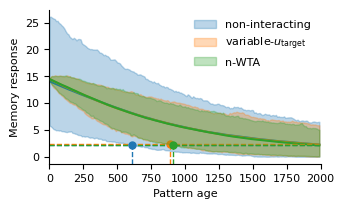

In [8]:
plt.rcParams.update({
    "font.size": 8,
    "axes.labelsize": 8,
    "axes.titlesize": 8,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
})

fig, ax = plt.subplots(figsize=(3.5, 2.0))
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

xmax = 2000
plot_point_spacing = 10
ax.fill_between(np.arange(0, xmax, plot_point_spacing), upper99_transient_1[::plot_point_spacing], lower01_transient_1[::plot_point_spacing], color='C0', alpha=0.3, label='non-interacting', zorder=1)
# ax.plot(np.arange(0, xmax, plot_point_spacing), mean_transient_1[::plot_point_spacing])
    
ax.fill_between(np.arange(0, xmax, plot_point_spacing), upper99_transient_2[::plot_point_spacing], lower01_transient_2[::plot_point_spacing], color='C1', alpha=0.3, label=r'variable-$u_{\text{target}}$', zorder=2)
# ax.plot(np.arange(0, xmax, plot_point_spacing), mean_transient_2[::plot_point_spacing])
ax.fill_between(np.arange(0, xmax, plot_point_spacing), upper99_transient_3[::plot_point_spacing], lower01_transient_3[::plot_point_spacing], color='C2', alpha=0.3, label='n-WTA', zorder=3)

ax.plot(np.arange(0, xmax, plot_point_spacing), mean_transient_1[::plot_point_spacing])
ax.plot(np.arange(0, xmax, plot_point_spacing), mean_transient_2[::plot_point_spacing])
ax.plot(np.arange(0, xmax, plot_point_spacing), mean_transient_3[::plot_point_spacing])

y_min, y_max = ax.get_ylim()

ax.hlines(y=upper99_1[0], xmin=0, xmax=xmax, colors='C0', linestyles='--', linewidth=1.)
ax.vlines(x=capa_1[0], ymin=y_min, ymax=upper99_1[0], colors='C0', linestyles='--', linewidth=1.)
ax.hlines(y=upper99_2[0], xmin=0, xmax=xmax, colors='C1', linestyles='--', linewidth=1.)
ax.vlines(x=capa_2[0], ymin=y_min, ymax=upper99_2[0], colors='C1', linestyles='--', linewidth=1.)
ax.hlines(y=upper99_3[0], xmin=0, xmax=xmax, colors='C2', linestyles='--', linewidth=1.)
ax.vlines(x=capa_3[0], ymin=y_min, ymax=upper99_3[0], colors='C2', linestyles='--', linewidth=1.)
ax.plot(capa_1, upper99_1, color='C0', marker='o', markersize=5)
ax.plot(capa_2, upper99_2, color='C1', marker='o', markersize=5)
ax.plot(capa_3, upper99_3, color='C2', marker='o', markersize=5)

ax.set_xlim(0, xmax)
ax.set_ylim(y_min, y_max)

ax.set_xlabel("Pattern age");
ax.set_ylabel("Memory response");

ax.legend(fontsize=8, frameon=False)

# plt.savefig("../figures/fig2/memory_response_vs_age_coeff_infty_params3.pdf", bbox_inches="tight")